# App Store rating classification: Endterm

**Students:** Nurtilek Koblandy; Erkebulan Zhuparbay; Mansur Ryskali. **Group:** SE-2423.

This notebook reruns the real frozen API experiment. It performs no network collection. The November snapshot is a **separate experiment**: the original Midterm raw data and split were lost. The original-data continuity criterion remains unresolved. All eight methods below share the saved split of this new snapshot.

Use the private submission archive to obtain the data. Select the project virtual environment, then Restart and Run All. Runtime is several minutes on a typical CPU.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from appstore_ml.endterm import experiment
OUT = ROOT / 'outputs/endterm'
RUN = ROOT / 'work/endterm-2026-11-08'
assert (RUN / 'data/raw').is_dir(), 'Restore the private frozen run before execution.'

## Research question and locked analysis

Can seven metadata inputs distinguish rating >=4.5 from <4.5 among existing US apps with at least 50 ratings? Five numeric features and two categorical features enter fold-fitted preprocessing. Ratings, rating counts, identifiers and text are excluded. F1 for class 1 is primary, with AUC, balanced accuracy and class-0 recall to expose imbalance. Forest and boosting use nested CV (5 outer / 3 inner folds). The MLP has fixed settings and training-only learning diagnostics. No hyperparameter or threshold choice uses test rows.

In [2]:
provenance = experiment(RUN, OUT, new_experiment=True, render=False)
print('Data status:', provenance['data_kind'])
print('Experiment:', provenance['experiment_id'])
print('Saved split:', provenance['train_n'], '/', provenance['test_n'])
print('CV-selected model:', provenance['selected_model'])

Frozen snapshot: 2179 apps, 1743 train / 436 test


Endterm Dummy: 5 outer folds, fixed settings


  fold 1: F1=0.8868


  fold 2: F1=0.8868


  fold 3: F1=0.8885


  fold 4: F1=0.8882


... (49 outputs left out)

  fold 4: F1=0.8663


  fold 5: F1=0.8785


MLP: CV F1=0.8746 +/- 0.0069


Data status: real_api
Experiment: endterm-2026-11-08
Saved split: 1743 / 436
CV-selected model: SVM


## Data, continuity and model selection

In [3]:
for name in ['cleaning_audit.json', 'continuity.json', 'model_selection.json']:
    display(Markdown('### ' + name))
    display(json.loads((OUT / 'reports' / name).read_text()))

### cleaning_audit.json

{'raw_rows': 2944,
 'excluded': {'invalid_track_id': 0,
  'invalid_collection_time': 0,
  'not_software': 0,
  'duplicate_track_id': 293,
  'non_usd_or_missing_currency': 0,
  'invalid_or_below_50_ratings': 472,
  'invalid_or_missing_rating': 0},
 'clean_rows': 2179,
 'class_counts': {'0': 440, '1': 1739},
 'missing_features': {'price_usd': 0,
  'size_mb': 0,
  'language_count': 0,
  'release_year': 0,
  'update_recency_days': 0,
  'primary_genre': 0,
  'content_advisory_rating': 0},
 'missing_description': 0,
 'collection_start': '2026-11-07T21:10:17.817609+00:00',
 'collection_end': '2026-11-07T21:11:17.899026+00:00',
 'minimum_met': True}

### continuity.json

{'original_dataset_sha256': '5c4169bb4bf7cf5f8ae8c14110dc8aef6948a645657b869ff77c21c4631bc8fd',
 'current_dataset_sha256': 'fe329f600227b87391b4c48d2d7c4db3dd9c10297503402ff151e36687348676',
 'same_dataset': False,
 'same_original_split_verified': False,
 'status': 'separate_experiment',
 'limitation': 'The original private split manifest is unavailable. A new split cannot establish continuity, even if its seed is the same. No instructor exception is claimed.'}

### model_selection.json

{'selected_model': 'SVM',
 'best_earlier_model': 'SVM',
 'best_repeated_midterm_model': 'SVM',
 'original_midterm_selected_model': 'SVM',
 'criterion': 'maximum mean outer CV F1 for class 1',
 'tie_break': 'model name ascending',
 'cv_std': 'sample standard deviation, ddof=1',
 'outer_folds': 5,
 'inner_folds': 3,
 'hyperparameter_tuning': 'nested training CV for ensembles; full-training CV for final refit',
 'inner_tie_break': 'first candidate in deterministic sklearn ParameterGrid order',
 'search_spaces': {'Random Forest': {'model__max_depth': [None, 12],
   'model__min_samples_leaf': [2, 10],
   'model__max_features': ['sqrt', 0.8]},
  'Gradient Boosting': {'model__n_estimators': [75, 150],
   'model__learning_rate': [0.03, 0.1],
   'model__max_depth': [1, 2]}},
 'selected_parameters': {'Dummy': {'fixed_estimator': "DummyClassifier(strategy='most_frequent')"},
  'Decision Tree': {'fixed_estimator': 'DecisionTreeClassifier(max_depth=8, min_samples_leaf=10, random_state=42)'},
  'KNN

## One comparison on the saved split

CV spread is sample SD, not a confidence interval. For tuned ensembles, outer folds evaluate the complete tuning procedure. Winning CV scores may still be optimistic after model-family selection.

In [4]:
display(pd.read_csv(OUT / 'reports/comparison.csv').round(4))
display(pd.read_csv(OUT / 'reports/tuning_results.csv').round(4))

,model,cv_scheme,cv_f1_mean,cv_f1_std,cv_roc_auc_mean,cv_roc_auc_std,cv_precision_mean,cv_precision_std,cv_recall_mean,cv_recall_std,...,f1,roc_auc,precision,recall,balanced_accuracy,specificity,tn,fp,fn,tp
0,Dummy,fixed settings,0.8877,0.0009,0.5000,0.0000,0.7981,0.0014,1.0000,0.0000,...,0.8878,0.5000,0.7982,1.0000,0.5000,0.0000,0,88,0,348
1,Decision Tree,fixed settings,0.8638,0.0165,0.6561,0.0487,0.8239,0.0113,0.9080,0.0266,...,0.8748,0.5774,0.8228,0.9339,0.5692,0.2045,18,70,23,325
2,KNN,fixed settings,0.8887,0.0043,0.6931,0.0488,0.8219,0.0068,0.9677,0.0173,...,0.8678,0.6508,0.8105,0.9339,0.5351,0.1364,12,76,23,325
3,SVM,fixed settings,0.8926,0.0031,0.6805,0.0391,0.8117,0.0046,0.9914,0.0070,...,0.8872,0.6433,0.8085,0.9828,0.5312,0.0795,7,81,6,342
4,Random Forest,nested,0.8882,0.0025,0.7365,0.0340,0.8089,0.0074,0.9849,0.0142,...,0.8874,0.6978,0.8231,0.9626,0.5722,0.1818,16,72,13,335
5,Gradient Boosting,nested,0.8903,0.0016,0.7111,0.0329,0.8056,0.0007,0.9950,0.0041,...,0.8909,0.6436,0.8051,0.9971,0.5213,0.0455,4,84,1,347
6,SVM + PCA,fixed settings,0.8919,0.0022,0.6577,0.0297,0.8091,0.0021,0.9935,0.0039,...,0.8889,0.6191,0.8075,0.9885,0.5283,0.0682,6,82,4,344
7,MLP,fixed settings,0.8746,0.0069,0.7180,0.0382,0.8382,0.0137,0.9145,0.0077,...,0.8639,0.6449,0.8360,0.8937,0.6002,0.3068,27,61,37,311


,model,scope,parameters,mean_validation_f1,validation_f1_sample_sd,mean_training_f1,rank,selected
0,Random Forest,outer_fold_1,"{""model__max_depth"": null, ""model__max_feature...",0.8886,0.0010,0.9353,3,False
1,Random Forest,outer_fold_1,"{""model__max_depth"": null, ""model__max_feature...",0.8883,0.0012,0.8886,4,False
2,Random Forest,outer_fold_1,"{""model__max_depth"": null, ""model__max_feature...",0.8797,0.0072,0.9789,7,False
3,Random Forest,outer_fold_1,"{""model__max_depth"": null, ""model__max_feature...",0.8868,0.0066,0.9015,5,False
4,Random Forest,outer_fold_1,"{""model__max_depth"": 12, ""model__max_features""...",0.8916,0.0023,0.9170,1,True
...,...,...,...,...,...,...,...,...
91,Gradient Boosting,full_training_refit,"{""model__learning_rate"": 0.03, ""model__max_dep...",0.8886,0.0026,0.9002,5,False
92,Gradient Boosting,full_training_refit,"{""model__learning_rate"": 0.1, ""model__max_dept...",0.8895,0.0017,0.8938,3,False
93,Gradient Boosting,full_training_refit,"{""model__learning_rate"": 0.1, ""model__max_dept...",0.8891,0.0014,0.8946,4,False
94,Gradient Boosting,full_training_refit,"{""model__learning_rate"": 0.1, ""model__max_dept...",0.8851,0.0025,0.9068,7,False


## PCA structure and its predictive check

Descriptive PCA uses training rows only. The SVM + PCA comparison refits PCA inside every CV fold. Two-dimensional density does not establish natural app categories.

{'method': 'PCA; full SVD; training data only',
 'train_n': 1743,
 'raw_input_count': 7,
 'transformed_feature_count': 33,
 'components_for_90_percent': 9,
 'first_two_explained_variance': 0.36588156866114685,
 'pc1_explained_variance': 0.19494041945399118,
 'pc2_explained_variance': 0.17094114920715567,
 'dominant_loadings': {'PC1': [{'feature': 'numeric__size_mb',
    'loading': 0.6060824271560333},
   {'feature': 'numeric__update_recency_days', 'loading': -0.543087059767255},
   {'feature': 'numeric__release_year', 'loading': 0.4654032198964741},
   {'feature': 'numeric__language_count', 'loading': 0.2904655574861357},
   {'feature': 'categorical__primary_genre_Games',
    'loading': 0.11911797781414163}],
  'PC2': [{'feature': 'numeric__language_count',
    'loading': 0.6239431064867202},
   {'feature': 'numeric__price_usd', 'loading': 0.5967474165223969},
   {'feature': 'numeric__release_year', 'loading': -0.4940010301538703},
   {'feature': 'numeric__size_mb', 'loading': 0.071334

,pc1_stratum,n,median_price_usd,median_size_mb,median_language_count,median_release_year,median_update_recency_days,most_common_genre
0,1,436,0.0,105.749504,2.0,2013.0,136.0,Weather
1,2,436,0.0,164.331520,2.0,2016.0,12.0,Health & Fitness
2,3,435,0.0,206.621696,7.0,2019.0,12.0,Games
3,4,436,0.0,382.586880,13.0,2022.0,9.0,Games


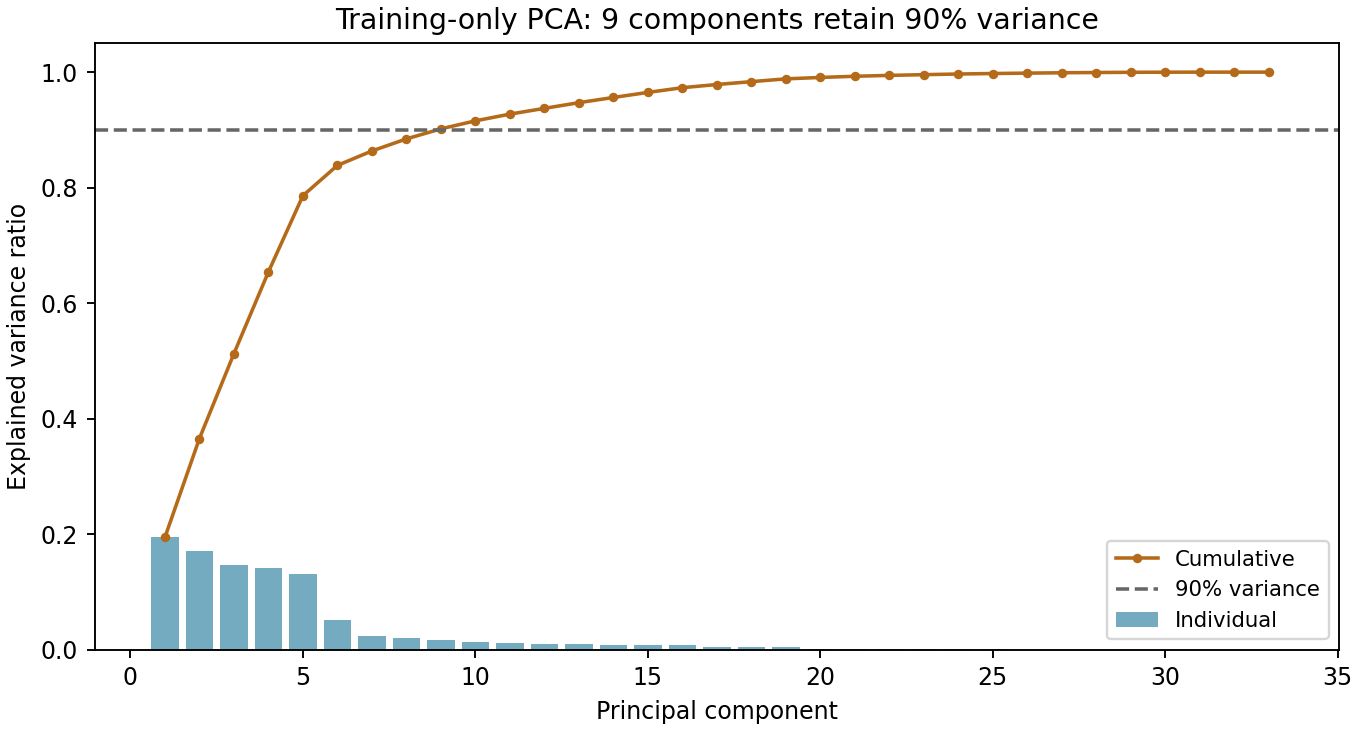

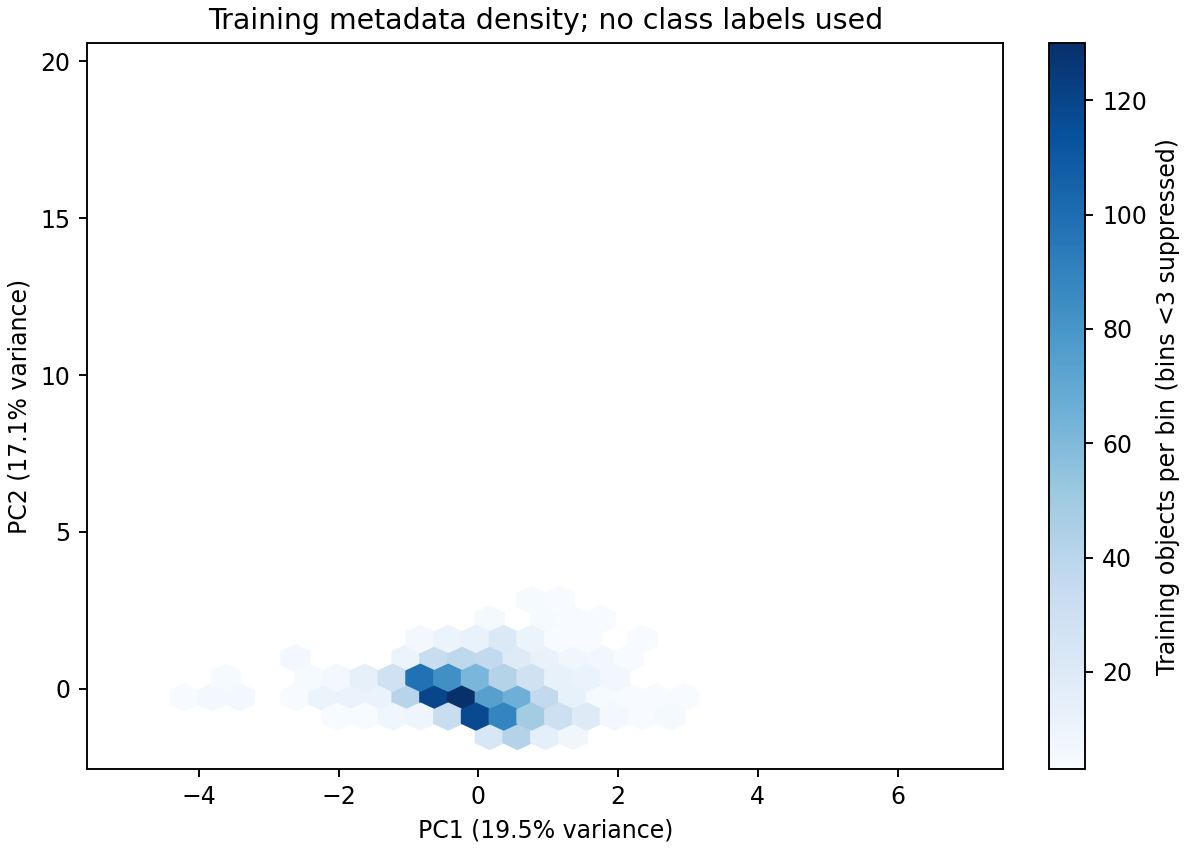

In [5]:
display(json.loads((OUT / 'reports/unsupervised.json').read_text()))
display(pd.read_csv(OUT / 'reports/pca_profiles.csv'))
display(Image(filename=str(OUT / 'figures/pca_variance.png')))
display(Image(filename=str(OUT / 'figures/pca_map.png')))

## MLP learning

The diagnostic split is within training. Its imputer, encoder and scaler exclude the diagnostic validation rows. The fixed epoch count is not tuned on these curves or on test performance.

In [6]:
display(json.loads((OUT / 'reports/mlp_diagnostics.json').read_text()))
learning = pd.read_csv(OUT / 'reports/mlp_learning_curve.csv')
display(learning.iloc[[0, -1]])
learning.set_index('epoch').filter(like='loss').plot(title='Training-only MLP diagnostic')

{'architecture': [32, 16],
 'activation': 'relu',
 'optimizer': 'adam',
 'alpha': 0.001,
 'learning_rate_init': 0.001,
 'batch_size': 64,
 'fixed_epochs': 120,
 'early_stopping': False,
 'diagnostic_training_n': 1394,
 'diagnostic_validation_n': 349,
 'validation_source': 'stratified 20% of the saved training partition',
 'preprocessing_fit_scope': 'diagnostic training subset only',
 'used_to_change_settings': False,
 'test_used': False,
 'best_observed_validation_epoch': 35,
 'best_observed_validation_log_loss': 0.4215418980058129,
 'final_training_log_loss': 0.29457376967038074,
 'final_validation_log_loss': 0.4882021894846762,
 'final_validation_f1': 0.8758620689655172,
 'validation_loss_change_last_window': 0.011021489766739834,
 'window_epochs': 10,
 'validation_loss_above_observed_minimum': 0.06666029147886332,
 'interpretation_rule': 'Lower training loss with increasing validation loss suggests overfitting. A flat validation loss suggests a plateau; fixed-budget termination alon

,epoch,training_log_loss,validation_log_loss,training_f1,validation_f1
0,1,0.584326,0.595039,0.881998,0.881029
119,120,0.294574,0.488202,0.926037,0.875862


<Axes: title={'center': 'Training-only MLP diagnostic'}, xlabel='epoch'>

## Real errors across all models

Public examples use coarse descriptions. App IDs, exact ratings, descriptions and detailed predictions are retained only in the private archive.

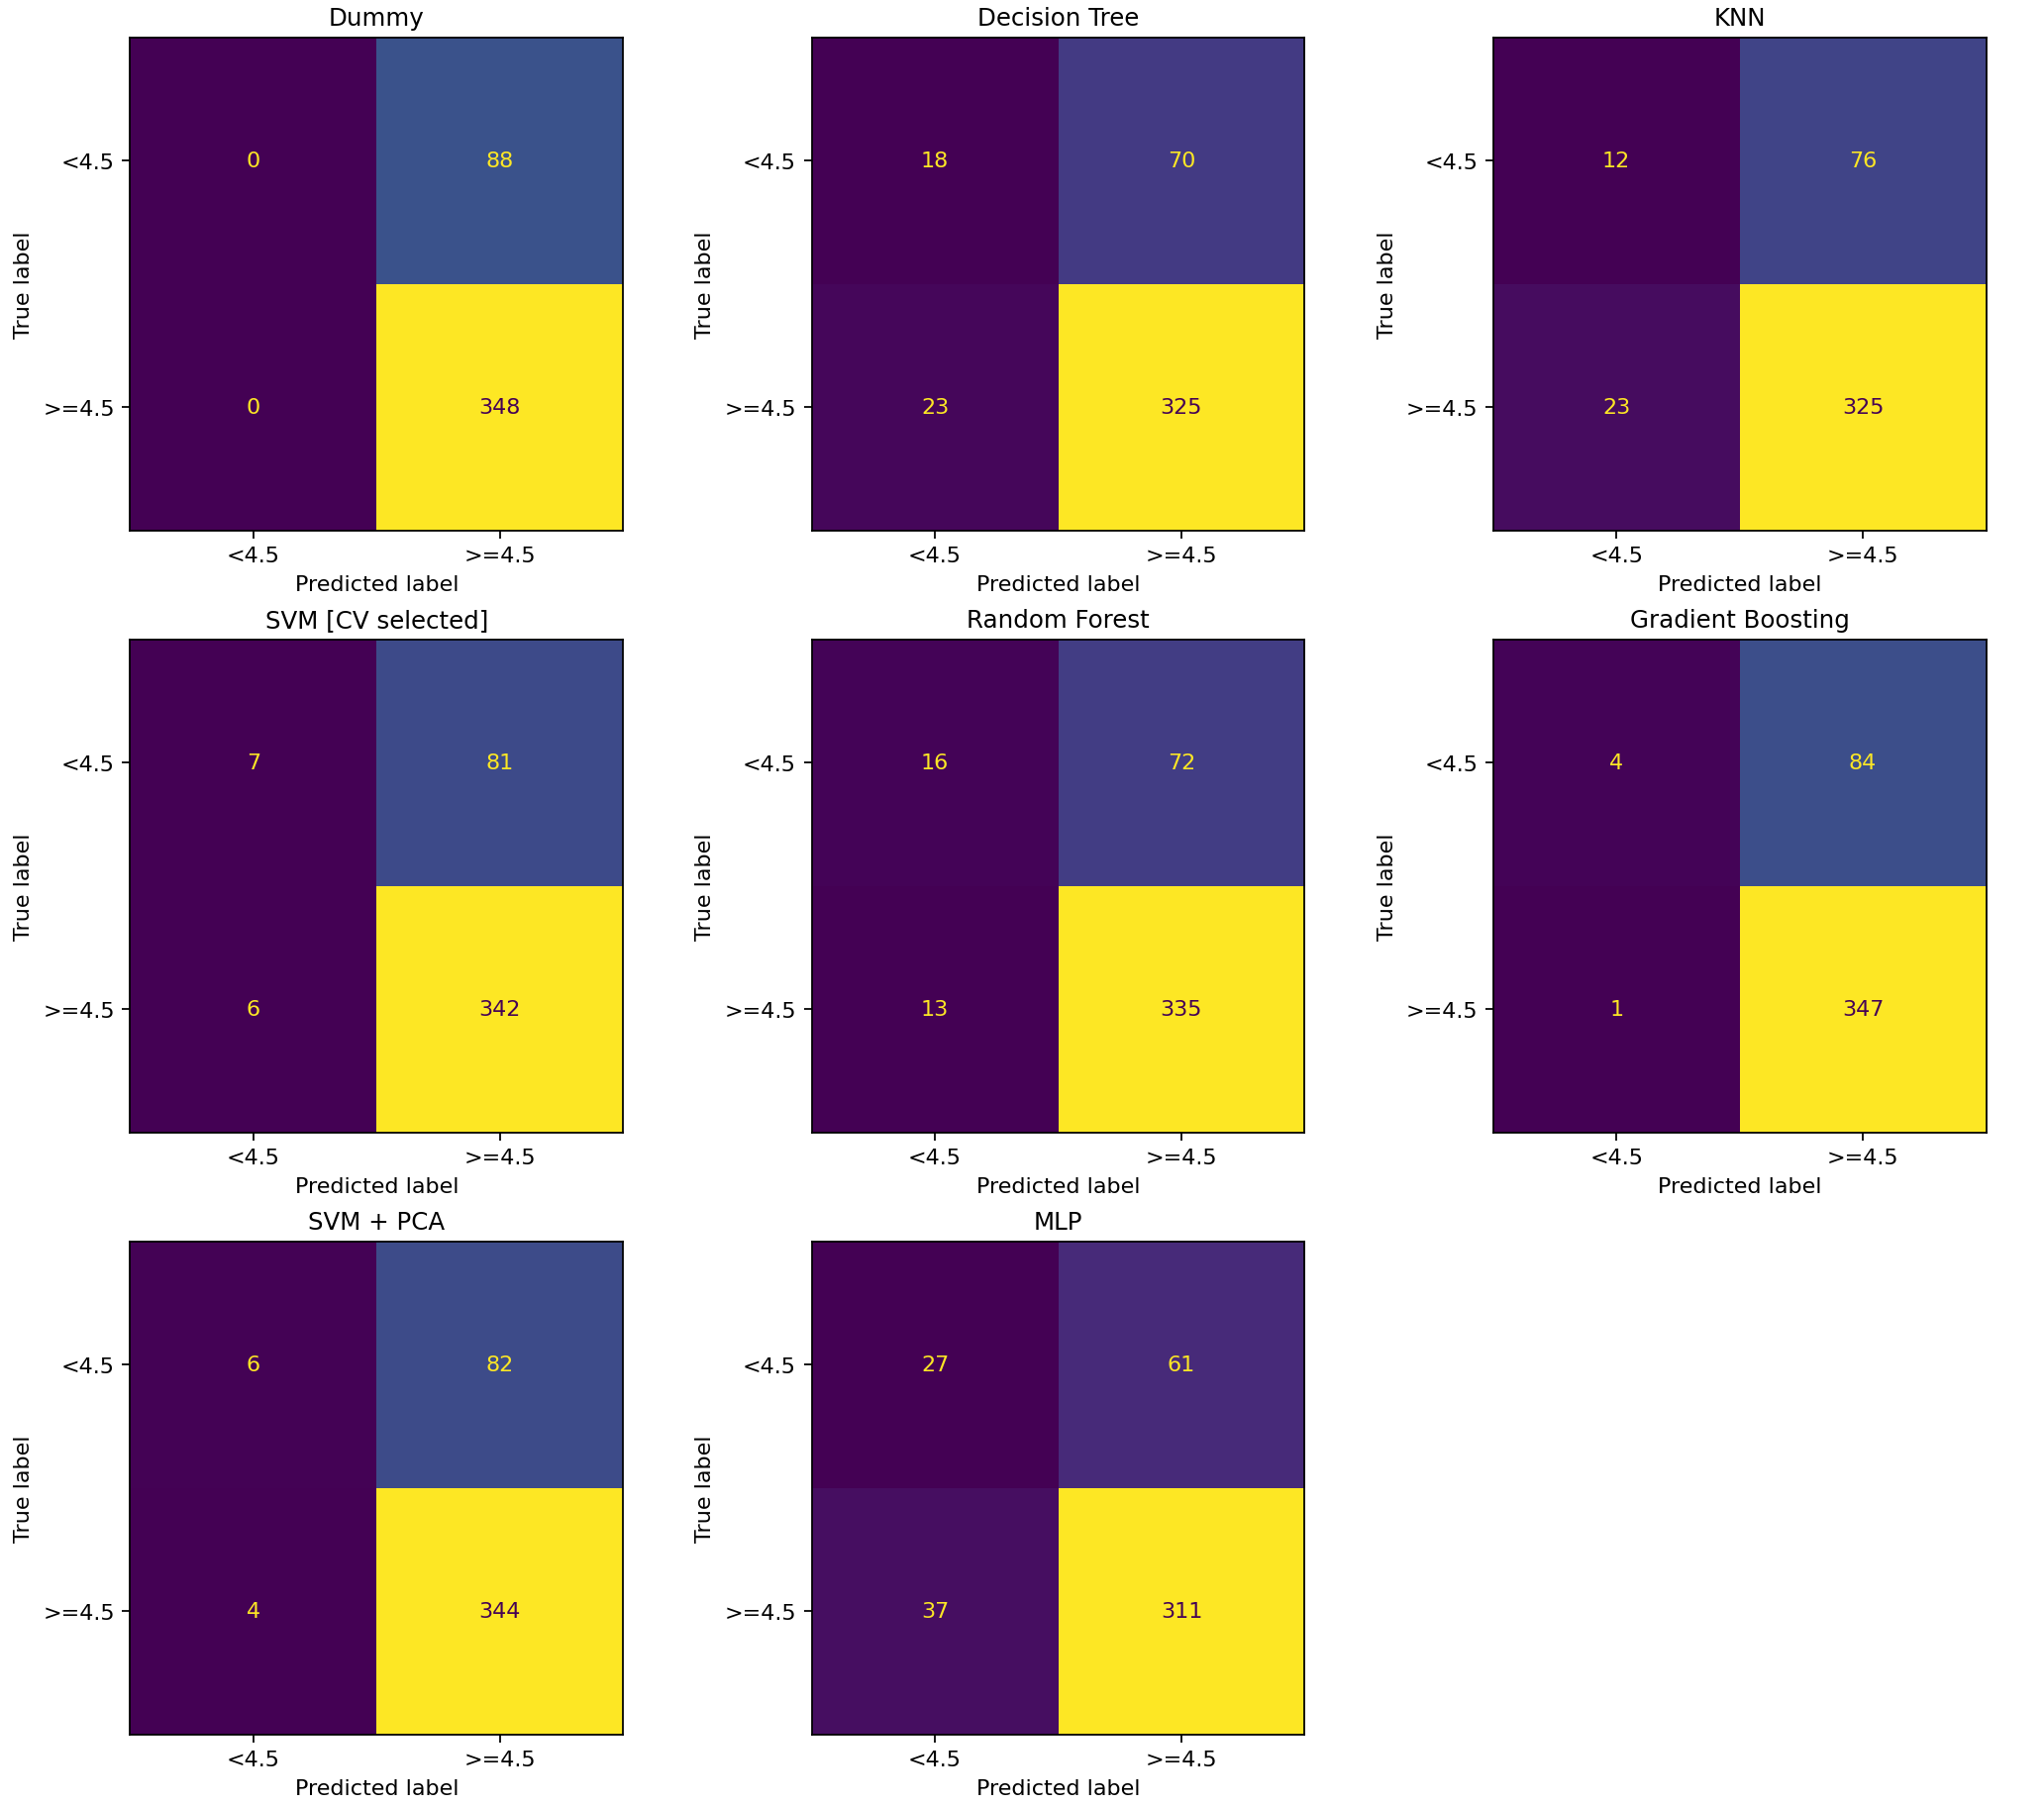

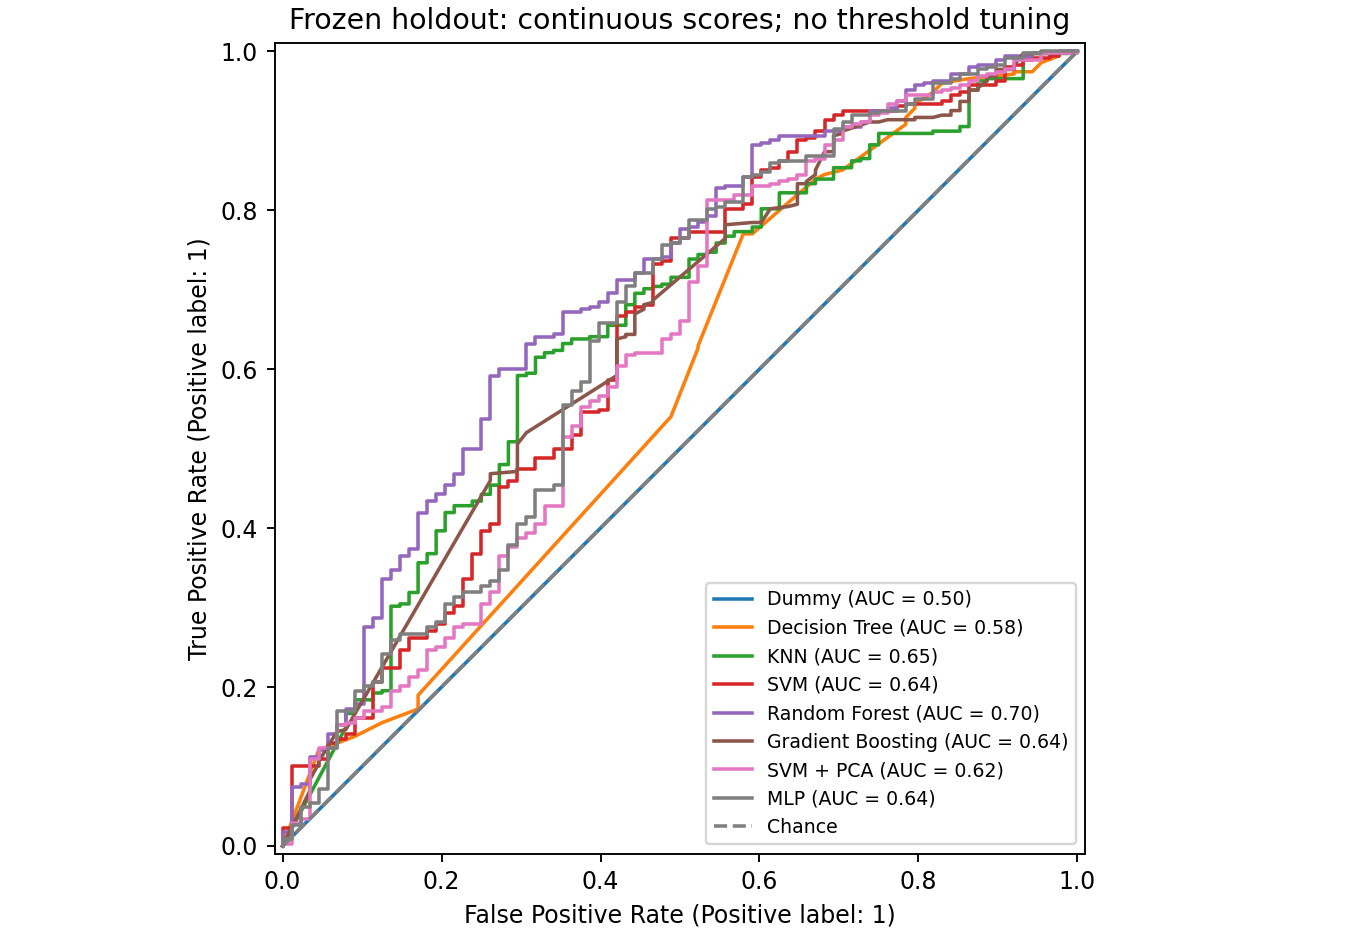

,model,case,error_type,actual_class,predicted_class,observation,interpretation
0,Dummy,FP example 1,FP,0,1,size in training upper quartile; update recenc...,Observed metadata association; the cause of th...
1,Dummy,FP example 2,FP,0,1,size in training lower quartile; update recenc...,Observed metadata association; the cause of th...
2,Decision Tree,FP example 1,FP,0,1,size in training upper quartile; update recenc...,Observed metadata association; the cause of th...
3,Decision Tree,FP example 2,FP,0,1,size in training lower quartile; update recenc...,Observed metadata association; the cause of th...
4,Decision Tree,FN example 1,FN,1,0,size in training middle half; update recency i...,Observed metadata association; the cause of th...
5,Decision Tree,FN example 2,FN,1,0,size in training lower quartile; update recenc...,Observed metadata association; the cause of th...
6,KNN,FP example 1,FP,0,1,size in training upper quartile; update recenc...,Observed metadata association; the cause of th...
7,KNN,FP example 2,FP,0,1,size in training lower quartile; update recenc...,Observed metadata association; the cause of th...
8,KNN,FN example 1,FN,1,0,size in training upper quartile; update recenc...,Observed metadata association; the cause of th...
9,KNN,FN example 2,FN,1,0,size in training lower quartile; update recenc...,Observed metadata association; the cause of th...


,model,reference,test_n,both_correct,both_wrong,model_only_correct,svm_only_correct,prediction_disagreements,interpretation
0,Dummy,SVM,436,342,81,6,7,13,Paired descriptive counts; not a significance ...
1,Decision Tree,SVM,436,326,70,17,23,40,Paired descriptive counts; not a significance ...
2,KNN,SVM,436,330,80,7,19,26,Paired descriptive counts; not a significance ...
3,SVM,SVM,436,349,87,0,0,0,Paired descriptive counts; not a significance ...
4,Random Forest,SVM,436,339,75,12,10,22,Paired descriptive counts; not a significance ...
5,Gradient Boosting,SVM,436,346,82,5,3,8,Paired descriptive counts; not a significance ...
6,SVM + PCA,SVM,436,347,84,3,2,5,Paired descriptive counts; not a significance ...
7,MLP,SVM,436,316,65,22,33,55,Paired descriptive counts; not a significance ...


,model,genre,test_n,errors,fp,fn,error_rate
0,Dummy,Education,57,15,15,0,0.263158
1,Dummy,Finance,29,6,6,0,0.206897
2,Dummy,Games,94,27,27,0,0.287234
3,Dummy,Health & Fitness,51,4,4,0,0.078431
4,Dummy,Music,30,6,6,0,0.200000
...,...,...,...,...,...,...,...
59,MLP,Health & Fitness,51,5,4,1,0.098039
60,MLP,Music,30,8,5,3,0.266667
61,MLP,Photo & Video,23,4,3,1,0.173913
62,MLP,Shopping,33,2,2,0,0.060606


In [7]:
display(Image(filename=str(OUT / 'figures/confusion_matrices.png')))
display(Image(filename=str(OUT / 'figures/roc_curves.png')))
display(pd.read_csv(OUT / 'reports/error_cases_anonymized.csv'))
display(pd.read_csv(OUT / 'reports/paired_errors.csv'))
display(pd.read_csv(OUT / 'reports/error_profiles.csv'))

## Interpretation, limitations and Final plan

Use the generated Endterm report for the complete result interpretation. A convenience sample of established apps does not establish pre-launch prediction or causal explanations. Developer overlap and temporal drift remain limitations. For Final, investigate retained app descriptions linked privately by trackId, only after confirming permission or choosing a suitably licensed replacement. Compare train-fold TF-IDF plus a linear model with metadata-only and combined models, with the same frozen IDs and training-only selection. Keep raw text private. Do not reuse this examined test set for unlimited adaptive model choices.

AI use: Codex assisted with code, tests, collection execution, analysis and writing. Students must record their real contributions and explain every part independently. No student names, hours or instructor exceptions are inferred.

## Team responsibilities

These roles were assigned at the owner's request. They do not certify completed contributions. Each student must review the relevant code and results and confirm their own completed work.

| Student | Assigned responsibility | Slides |
| --- | --- | --- |
| Nurtilek Koblandy | Data preparation, provenance, leakage checks and baseline models | 1-3 |
| Erkebulan Zhuparbay | Ensemble tuning, model comparison and PCA analysis | 4-6 |
| Mansur Ryskali | MLP learning checks, error analysis, conclusions and Final plan | 7-9 |

The rubric describes two partners. Instructor acceptance of the three-person team has not been provided.